In [101]:

import os
import sys
import pandas as pd
import seaborn as sns
# from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
import numpy as np



pd.set_option('display.max_columns', None)

# Look one folder up from 'presentation/' to get to the project root
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Enable automatic reloading so changes to the code apply instantly
%load_ext autoreload
%autoreload 2

from src.utils import load_csv_as_dataframe

   
df_raw = load_csv_as_dataframe("kc_house_data.csv")
df     = df_raw.copy()


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [102]:
# Check the number of rows and columns
rows, columns = df.shape

print(f"There are {rows} rows and {columns} columns")



There are 21613 rows and 21 columns


Inspect the Column Names.

In [103]:
df.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='str')

Inspect Data Types

In [104]:
df.dtypes

id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

### Check for Missing Values and Duplicate Rows

Create reusable functions to check the dataset for missing cells and exact duplicate rows. These checks help identify potential data-quality issues before cleaning and analysis.

In [105]:
def count_missing_values(df: pd.DataFrame) -> int:
    """Count all missing cells in a DataFrame."""
    num_missing_values = df.isnull().sum().sum()

    if num_missing_values > 0:
        print(f"Number of missing values found: {num_missing_values}")
    else:
        print("There are no missing values.")

    return num_missing_values


def count_duplicated_rows(df: pd.DataFrame) -> int:
    """Count rows that duplicate an earlier row exactly."""
    num_duplicated_rows = df.duplicated().sum()

    if num_duplicated_rows > 0:
        print(f"Number of duplicated rows found: {num_duplicated_rows}")
    else:
        print("There are no duplicated rows.")

    return num_duplicated_rows

In [106]:
count_missing_values(df)

There are no missing values.


np.int64(0)

In [107]:
count_duplicated_rows(df)

There are no duplicated rows.


np.int64(0)

In [108]:
# Display the first five rows

df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [109]:
# Display the last five rows
df.tail()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287
21612,1523300157,20141015T000000,325000.0,2,0.75,1020,1076,2.0,0,0,3,7,1020,0,2008,0,98144,47.5941,-122.299,1020,1357


Descriptive Statistics of Numeric Columns

In [110]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


### Investigate Minimum Bedroom Values

Check the records with the fewest bedrooms to determine whether any values need further investigation before modelling.

In [111]:
# Find the row with the fewest bedrooms
min_bedrooms_index = df["bedrooms"].idxmin()

# Display relevant property details
df.loc[
    min_bedrooms_index,
    ["price", "bedrooms", "bathrooms", "sqft_living", "grade"]
]

price          1095000.0
bedrooms             0.0
bathrooms            0.0
sqft_living       3064.0
grade                7.0
Name: 875, dtype: float64

### Examine Bedroom Counts

Count the number of properties for each bedroom value and sort the results in ascending order. This helps identify unusual values that may require further investigation before model training.

In [112]:
df["bedrooms"].value_counts().sort_index()

bedrooms
0       13
1      199
2     2760
3     9824
4     6882
5     1601
6      272
7       38
8       13
9        6
10       3
11       1
33       1
Name: count, dtype: int64

Why are we checking this?

From the data, we know that 10 records have zero bathrooms. We want to understand how common each bathroom count is and investigate whether a value of zero represents a genuine property characteristic or a potential data-quality issue.

Bathroom counts can sometimes be represented as fractional values, such as 1.5 or 1.75, depending on how the dataset defines and records bathrooms. These values may reflect differences in bathroom facilities or the way bathroom counts are recorded. Therefore, we should not assume that every bathroom count must be a whole number. 

Instead, we should examine the distribution of values and investigate any unusual or unexpected entries.

In [113]:
#Examine Bathroom Counts
df["bathrooms"].value_counts()

bathrooms
2.50    5380
1.00    3852
1.75    3048
2.25    2047
2.00    1930
1.50    1446
2.75    1185
3.00     753
3.50     731
3.25     589
3.75     155
4.00     136
4.50     100
4.25      79
0.75      72
4.75      23
5.00      21
5.25      13
0.00      10
5.50      10
1.25       9
6.00       6
0.50       4
5.75       4
6.75       2
8.00       2
6.25       2
6.50       2
7.50       1
7.75       1
Name: count, dtype: int64

### What zero bathroom means to me?

The percentage is very small, but that does not automatically mean the records are errors or can be ignored. More investigate is needed before deciding how to handle them.

In [114]:
zero_bathrooms = (df['bathrooms'] == 0).sum()
total_records = len(df)

percentage = (zero_bathrooms / total_records) * 100

print("Records with zero bathrooms:", zero_bathrooms)
print("Total records:", total_records)
print(f"Percentage: {percentage:.4f}%")

Records with zero bathrooms: 10
Total records: 21613
Percentage: 0.0463%


Inspect DataFrame Structure

In [115]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

### Examine Renovation-Year Values

Count the number of properties associated with each renovation year. In this dataset, zero represents properties with no recorded renovation year, so it should be interpreted carefully rather than automatically treated as a missing value.

In [116]:
# Count houses by renovation year
renovation_year_counts = df["yr_renovated"].value_counts().sort_index()
print(renovation_year_counts)

yr_renovated
0       20699
1934        1
1940        2
1944        1
1945        3
        ...  
2011       13
2012       11
2013       37
2014       91
2015       16
Name: count, Length: 70, dtype: int64


### Descriptive Statistics for Selected Numerical Columns

In [117]:
df[["price", "bathrooms", "sqft_living", "sqft_lot", "yr_built", "yr_renovated"]].describe()

,price,bathrooms,sqft_living,sqft_lot,yr_built,yr_renovated
count,2.161300e+04,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000
mean,5.400881e+05,2.114757,2079.899736,1.510697e+04,1971.005136,84.402258
std,3.671272e+05,0.770163,918.440897,4.142051e+04,29.373411,401.679240
min,7.500000e+04,0.000000,290.000000,5.200000e+02,1900.000000,0.000000
25%,3.219500e+05,1.750000,1427.000000,5.040000e+03,1951.000000,0.000000
50%,4.500000e+05,2.250000,1910.000000,7.618000e+03,1975.000000,0.000000
75%,6.450000e+05,2.500000,2550.000000,1.068800e+04,1997.000000,0.000000
max,7.700000e+06,8.000000,13540.000000,1.651359e+06,2015.000000,2015.000000


### Analyse Renovation Years

Filter the dataset to include only properties with a recorded renovation year. Calculate the percentage distribution of renovation years to understand how renovations are distributed among these properties.

In [118]:

renovated_subset = df[df["yr_renovated"] > 0]

# Get percentages for each specific year
year_percentages = renovated_subset["yr_renovated"].value_counts(normalize=True) * 100
print(year_percentages)


yr_renovated
2014    9.956236
2013    4.048140
2003    3.938731
2005    3.829322
2000    3.829322
          ...   
1948    0.109409
1951    0.109409
1959    0.109409
1934    0.109409
1944    0.109409
Name: proportion, Length: 69, dtype: float64


### Investigate Properties with Zero Bathrooms

Count properties recorded as having zero bathrooms and inspect their prices, bedroom counts, living areas and construction years to determine whether these records require further investigation before modelling.

In [119]:
# Count houses with zero bathrooms
print((df["bathrooms"] == 0).sum())

# Inspect the records
print(df.loc[df["bathrooms"] == 0, ["price", "bedrooms", "bathrooms", "sqft_living", "yr_built"]])




10
           price  bedrooms  bathrooms  sqft_living  yr_built
875    1095000.0         0        0.0         3064      1990
1149     75000.0         1        0.0          670      1966
3119    380000.0         0        0.0         1470      2006
5832    280000.0         1        0.0          600      1950
6994   1295650.0         0        0.0         4810      1990
9773    355000.0         0        0.0         2460      1990
9854    235000.0         0        0.0         1470      1996
10481   484000.0         1        0.0          690      1948
14423   139950.0         0        0.0          844      1913
19452   142000.0         0        0.0          290      1963


### Identify Properties with Zero Bedrooms and Bathrooms

In [120]:
# Count houses with zero bedrooms AND zero bathrooms
print(((df["bedrooms"] == 0) & (df["bathrooms"] == 0)).sum())




7


### Inspect the Date Column

Examine the first few date values and check the column's data type to determine whether the dates are stored as strings or as datetime values.

In [121]:
print(df["date"].head())
print(df["date"].dtype)

0    20141013T000000
1    20141209T000000
2    20150225T000000
3    20141209T000000
4    20150218T000000
Name: date, dtype: str
str


### Convert the Date Column to Datetime

Create a working copy of the dataset and convert the `date` column from its original representation into pandas datetime values, enabling date-based analysis and extraction of date components.

In [122]:
df_clean = df.copy()

df_clean["date"] = pd.to_datetime(df_clean["date"],format="%Y%m%dT%H%M%S")

### Verify Date Conversion

In [123]:
print(df_clean["date"].dtype)
print(df_clean["date"].head())

datetime64[us]
0   2014-10-13
1   2014-12-09
2   2015-02-25
3   2014-12-09
4   2015-02-18
Name: date, dtype: datetime64[us]


### Check the Date Range

Identify the earliest and latest sale dates to establish the period covered by the dataset and assess the relevance of the data for subsequent analysis and modelling.

In [124]:
print("Earliest sale:", df_clean["date"].min())
print("Latest sale:", df_clean["date"].max())


Earliest sale: 2014-05-02 00:00:00
Latest sale: 2015-05-27 00:00:00


### Check Property ID Uniqueness

Compare the number of unique property IDs with the total number of rows and count repeated ID occurrences. This helps determine whether the dataset contains multiple records associated with the same property.

In [125]:
# check for uniqness in ids

print("Unique IDs:", df_clean["id"].nunique())
print("Total rows:", len(df_clean))
print("Duplicate IDs:", df_clean["id"].duplicated().sum())

Unique IDs: 21436
Total rows: 21613
Duplicate IDs: 177


### Inspect Records with Repeated Property IDs

Select every record associated with a repeated property ID and sort the results by ID. Inspecting these records helps determine why IDs repeat and whether the records should be retained for analysis.

In [126]:
duplicate_ids = df_clean.loc[df_clean["id"].duplicated(keep=False)].sort_values("id")

print(duplicate_ids.head(10))

              id       date     price  bedrooms  bathrooms  sqft_living  \
2496     1000102 2014-09-16  280000.0         6       3.00         2400   
2497     1000102 2015-04-22  300000.0         6       3.00         2400   
16814    7200179 2014-10-16  150000.0         2       1.00          840   
16815    7200179 2015-04-24  175000.0         2       1.00          840   
11433  109200390 2014-08-20  245000.0         3       1.75         1480   
11434  109200390 2014-10-20  250000.0         3       1.75         1480   
12417  123039336 2014-06-11  148000.0         1       1.00          620   
12418  123039336 2014-12-08  244900.0         1       1.00          620   
7792   251300110 2014-07-31  225000.0         3       2.25         2510   
7793   251300110 2015-01-14  358000.0         3       2.25         2510   

       sqft_lot  floors  waterfront  view  condition  grade  sqft_above  \
2496       9373     2.0           0     0          3      7        2400   
2497       9373     2.0 

### Compare Property Details Across Repeated IDs

Group records by property ID and count the distinct values in each property characteristic. This identifies whether records sharing an ID describe consistent property details or contain differences that require further investigation.

In [127]:
property_columns = [
    "bedrooms", "bathrooms", "sqft_living",
    "sqft_lot", "floors", "waterfront", "view",
    "condition", "grade", "sqft_above",
    "sqft_basement", "yr_built", "yr_renovated",
    "zipcode", "lat", "long", "sqft_living15",
    "sqft_lot15"
]

print(
    duplicate_ids.groupby("id")[property_columns]
    .nunique()
    .max()
)

bedrooms         1
bathrooms        1
sqft_living      1
sqft_lot         1
floors           1
waterfront       1
view             1
condition        1
grade            1
sqft_above       1
sqft_basement    1
yr_built         1
yr_renovated     1
zipcode          1
lat              1
long             1
sqft_living15    1
sqft_lot15       1
dtype: int64


### Explore Correlations Between House Prices and Property Features

In [128]:
df_clean[["price", "sqft_living", "bedrooms", "grade"]].corr()

,price,sqft_living,bedrooms,grade
price,1.000000,0.702035,0.308350,0.667434
sqft_living,0.702035,1.000000,0.576671,0.762704
bedrooms,0.308350,0.576671,1.000000,0.356967
grade,0.667434,0.762704,0.356967,1.000000


### Examine House Sales by Month

Extract the month from each sale date and count the number of records for each month. This helps explore the monthly distribution of sales within the dataset's historical period.

In [129]:
df_clean["date"].dt.month.value_counts().sort_index()

date
1      978
2     1250
3     1875
4     2231
5     2414
6     2180
7     2211
8     1940
9     1774
10    1878
11    1411
12    1471
Name: count, dtype: int64

### Investigate the Highest House Prices

In [130]:
df_clean.nlargest(
    10, "price"
)[["price", "bedrooms", "bathrooms", "sqft_living", "grade", "zipcode"]]

,price,bedrooms,bathrooms,sqft_living,grade,zipcode
7252,7700000.0,6,8.00,12050,13,98102
3914,7062500.0,5,4.50,10040,11,98004
9254,6885000.0,6,7.75,9890,13,98039
4411,5570000.0,5,5.75,9200,13,98039
1448,5350000.0,5,5.00,8000,12,98004
1315,5300000.0,6,6.00,7390,12,98040
1164,5110800.0,5,5.25,8010,12,98033
8092,4668000.0,5,6.75,9640,12,98040
2626,4500000.0,5,5.50,6640,12,98155
8638,4489000.0,4,3.00,6430,12,98004


### Investigate the Most Expensive Property

Identify the property with the highest recorded sale price and inspect its characteristics to determine whether the price appears consistent with the property's features.

In [131]:
df_clean.loc[
    df_clean["price"].idxmax(),
    ["price", "bedrooms", "bathrooms", "sqft_living",
     "sqft_lot", "floors", "grade", "yr_built", "zipcode"]
]

price          7700000.0
bedrooms             6.0
bathrooms            8.0
sqft_living      12050.0
sqft_lot         27600.0
floors               2.5
grade               13.0
yr_built          1910.0
zipcode          98102.0
Name: 7252, dtype: float64

### Investigate the Least Expensive Properties

Identify the 10 properties with the lowest recorded sale prices and inspect their characteristics to assess whether the prices appear plausible given the available property details.

In [132]:
df_clean.nsmallest(
    10,
    "price"
)[
    ["price", "bedrooms", "bathrooms", "sqft_living",
     "sqft_lot", "floors", "grade", "yr_built", "zipcode"]
]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,grade,yr_built,zipcode
1149,75000.0,1,0.00,670,43377,1.0,3,1966,98022
15293,78000.0,2,1.00,780,16344,1.0,5,1942,98168
465,80000.0,1,0.75,430,5050,1.0,4,1912,98014
16198,81000.0,2,1.00,730,9975,1.0,5,1943,98168
8274,82000.0,3,1.00,860,10426,1.0,6,1954,98146
2141,82500.0,2,1.00,520,22334,1.0,5,1951,98168
18468,83000.0,2,1.00,900,8580,1.0,5,1918,98168
3767,84000.0,2,1.00,700,20130,1.0,6,1949,98168
10253,85000.0,2,1.00,830,9000,1.0,6,1939,98032
16714,85000.0,2,1.00,910,9753,1.0,5,1947,98032


### Examine Distributions of Property Features

Use a loop to count the occurrences of each value in the floors, waterfront, view, condition and grade columns. This helps assess the distributions and identify unusual values before modelling.

In [133]:
columns_to_check = [
    "floors",
    "waterfront",
    "view",
    "condition",
    "grade"
]

for column in columns_to_check:
    print(f"\n{column}")
    print(df_clean[column].value_counts().sort_index())


floors
floors
1.0    10680
1.5     1910
2.0     8241
2.5      161
3.0      613
3.5        8
Name: count, dtype: int64

waterfront
waterfront
0    21450
1      163
Name: count, dtype: int64

view
view
0    19489
1      332
2      963
3      510
4      319
Name: count, dtype: int64

condition
condition
1       30
2      172
3    14031
4     5679
5     1701
Name: count, dtype: int64

grade
grade
1        1
3        3
4       29
5      242
6     2038
7     8981
8     6068
9     2615
10    1134
11     399
12      90
13      13
Name: count, dtype: int64


### Analyse Construction and Renovation Years

Summarise the distributions of construction and renovation years, and count properties with a renovation year of zero. This helps identify unusual values and understand how renovation information is represented in the dataset.

In [134]:
print("Year built:")
print(df_clean["yr_built"].describe())

print("\nYear renovated:")
print(df_clean["yr_renovated"].describe())

print(
    "\nRenovated year is zero:",
    (df_clean["yr_renovated"] == 0).sum()
)

Year built:
count    21613.000000
mean      1971.005136
std         29.373411
min       1900.000000
25%       1951.000000
50%       1975.000000
75%       1997.000000
max       2015.000000
Name: yr_built, dtype: float64

Year renovated:
count    21613.000000
mean        84.402258
std        401.679240
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       2015.000000
Name: yr_renovated, dtype: float64

Renovated year is zero: 20699


### Examine Property Size and Location Features

Calculate descriptive statistics for property-size measurements and geographic coordinates. Transpose the results to make it easier to compare the distributions and identify values that may require further investigation.

In [135]:
columns_to_check = [
    "sqft_living",
    "sqft_lot",
    "sqft_above",
    "sqft_basement",
    "lat",
    "long",
    "sqft_living15",
    "sqft_lot15"
]

print(df_clean[columns_to_check].describe().T)

                 count          mean           std       min       25%  \
sqft_living    21613.0   2079.899736    918.440897  290.0000  1427.000   
sqft_lot       21613.0  15106.967566  41420.511515  520.0000  5040.000   
sqft_above     21613.0   1788.390691    828.090978  290.0000  1190.000   
sqft_basement  21613.0    291.509045    442.575043    0.0000     0.000   
lat            21613.0     47.560053      0.138564   47.1559    47.471   
long           21613.0   -122.213896      0.140828 -122.5190  -122.328   
sqft_living15  21613.0   1986.552492    685.391304  399.0000  1490.000   
sqft_lot15     21613.0  12768.455652  27304.179631  651.0000  5100.000   

                     50%        75%           max  
sqft_living    1910.0000   2550.000  1.354000e+04  
sqft_lot       7618.0000  10688.000  1.651359e+06  
sqft_above     1560.0000   2210.000  9.410000e+03  
sqft_basement     0.0000    560.000  4.820000e+03  
lat              47.5718     47.678  4.777760e+01  
long           -122.2

### Investigate Properties with the Largest Lots

Identify the five properties with the largest recorded lot sizes and inspect their prices, living areas, bedroom and bathroom counts, and geographic coordinates to assess whether the records appear plausible.

In [136]:
df_clean.nlargest(
    5,
    "sqft_lot"
)[
    [
        "price",
        "sqft_living",
        "sqft_lot",
        "bedrooms",
        "bathrooms",
        "lat",
        "long"
    ]
]

,price,sqft_living,sqft_lot,bedrooms,bathrooms,lat,long
1719,700000.0,1300,1651359,4,1.00,47.2313,-122.023
17319,190000.0,710,1164794,2,1.00,47.6888,-121.909
7647,542500.0,3010,1074218,5,3.25,47.4564,-122.004
7769,855000.0,4030,1024068,4,3.50,47.4619,-121.744
3949,998000.0,3770,982998,4,3.25,47.4140,-122.087


### Validate Living-Area Measurements

Compare total living area with the sum of above-ground and basement areas. Count any non-zero differences and identify the largest discrepancy to check for inconsistencies in the dataset.

In [137]:
sqft_difference = (
    df_clean["sqft_living"]  - df_clean["sqft_above"] - df_clean["sqft_basement"]
)

print("Rows where the difference is not zero:",
      (sqft_difference != 0).sum())

print("Largest absolute difference:",
      sqft_difference.abs().max())

Rows where the difference is not zero: 0
Largest absolute difference: 0


### Separate Features and Target

Create the feature matrix `X` by excluding the property ID, sale price and sale date. Define `y` as the sale price to be predicted. Check the resulting shapes and list the selected features before preparing the data for model training.

In [138]:
X = df_clean.drop(columns=["id", "price", "date"])
y = df_clean["price"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

X shape: (21613, 18)
y shape: (21613,)

Features:
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


### Create Date-Based Features

Extract the sale year and sale month from the converted date column and add them to the feature matrix `X`. These features allow the model to learn potential patterns in house prices over time. Check the updated shape and inspect the new columns to verify the changes.

In [139]:
X["sale_year"] = df_clean["date"].dt.year
X["sale_month"] = df_clean["date"].dt.month

print("Updated X shape:", X.shape)
print(X[["sale_year", "sale_month"]].head())

Updated X shape: (21613, 20)
   sale_year  sale_month
0       2014          10
1       2014          12
2       2015           2
3       2014          12
4       2015           2


### Handle Unusual Bedroom and Bathroom Values

Create a separate copy of the feature matrix and replace zero bedroom and bathroom counts with missing values. This allows the preprocessing pipeline to handle these values using an imputer during model training. The decision is a modelling assumption because some zero values may represent legitimate properties rather than data errors. Count the resulting missing values to verify the changes.

In [140]:
X_clean = X.copy()

X_clean.loc[X_clean["bedrooms"] == 0, "bedrooms"] = float("nan")
X_clean.loc[X_clean["bathrooms"] == 0, "bathrooms"] = float("nan")

print("Missing bedrooms:", X_clean["bedrooms"].isnull().sum())
print("Missing bathrooms:", X_clean["bathrooms"].isnull().sum())

Missing bedrooms: 13
Missing bathrooms: 10


In [141]:


# X_train, X_test, y_train, y_test = train_test_split(
#     X_clean,
#     y,
#     test_size=0.2,
#     random_state=42
# )

# print("Training features:", X_train.shape)
# print("Test features:", X_test.shape)
# print("Training targets:", y_train.shape)
# print("Test targets:", y_test.shape)

### Check for Repeated Property IDs

Count the total dataset rows, the number of unique property IDs, and the additional rows associated with previously seen IDs. These checks help determine whether a grouped train/test split is appropriate to reduce the risk of the same property appearing in both training and test sets.

In [142]:
print("Rows:", len(df_clean))
print("Unique property IDs:", df_clean["id"].nunique())
print("Repeated-ID rows:", df_clean["id"].duplicated().sum())

Rows: 21613
Unique property IDs: 21436
Repeated-ID rows: 177


### Split Data Using Property IDs

Split the feature matrix `X_clean` and target variable `y` into training and test sets using `GroupShuffleSplit`. Use the property IDs as groups to ensure that records sharing the same ID remain together in either the training set or the test set.

Reserve approximately 20% of the groups for testing and use `random_state=42` to make the split reproducible. Finally, print the shapes of the resulting feature and target sets to verify the split.

In [143]:

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_clean, y, groups=df_clean["id"])
)

X_train = X_clean.iloc[train_idx]
X_test = X_clean.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Test targets:", y_test.shape)

Training features: (17289, 20)
Test features: (4324, 20)
Training targets: (17289,)
Test targets: (4324,)


### Verify the Grouped Train/Test Split

Count the unique property IDs in the training and test sets, then check whether any IDs appear in both sets. The number of shared IDs should be zero, confirming that records with the same property ID have not been split across the two sets.

In [144]:
train_ids = df_clean["id"].iloc[train_idx]
test_ids = df_clean["id"].iloc[test_idx]

print("Unique training properties:", train_ids.nunique())
print("Unique test properties:", test_ids.nunique())
print("Properties in both sets:", len(set(train_ids) & set(test_ids)))

Unique training properties: 17148
Unique test properties: 4288
Properties in both sets: 0


### Impute Missing Values Using Training-Set Medians

Create a `SimpleImputer` that replaces missing values with the median of each feature. Fit the imputer on the training data only, then use the learned medians to transform both the training and test sets. This prevents information from the test set from influencing the imputation values. Preserve the original column names and row indices, and verify that no missing values remain.

In [145]:



# Create an imputer that replaces missing values with each column's median
imputer = SimpleImputer(strategy="median")

# Learn the medians from the training data, then fill its missing values
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Use those same medians to fill missing values in the test data
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing values in training data:", X_train_imputed.isnull().sum().sum())
print("Missing values in test data:", X_test_imputed.isnull().sum().sum())
print("Training shape:", X_train_imputed.shape)
print("Test shape:", X_test_imputed.shape)


Missing values in training data: 0
Missing values in test data: 0
Training shape: (17289, 20)
Test shape: (4324, 20)


### Inspect ZIP Code Values and Data Type

Count the distinct ZIP codes in the imputed training data and inspect the column's data type. ZIP codes represent locations rather than numerical quantities, so they should generally be handled as categorical features during preprocessing.

In [146]:

print("Unique ZIP codes:", X_train_imputed["zipcode"].nunique())
print("ZIP code data type:", X_train_imputed["zipcode"].dtype)


Unique ZIP codes: 70
ZIP code data type: float64


### Define Feature Preprocessing

Identify `zipcode` as a categorical feature and classify all remaining columns as numeric features. Create a `ColumnTransformer` that one-hot encodes ZIP codes while passing numeric features through unchanged. Configure the encoder to ignore previously unseen ZIP codes during transformation, and print the feature groups to verify the setup.

In [147]:
# ZIP codes are categories, not numerical measurements
categorical_features = ["zipcode"]

# All remaining columns are numeric features
numeric_features = [
    column for column in X_train_imputed.columns
    if column not in categorical_features
]

# Apply one-hot encoding to ZIP codes and keep other features unchanged
preprocessor = ColumnTransformer(
    transformers=[
        ("zipcode_encoder", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", "passthrough", numeric_features)
    ]
)

print("Categorical features:", categorical_features)
print("Number of numeric features:", len(numeric_features))


Categorical features: ['zipcode']
Number of numeric features: 19


### Transform Features for Model Training

Fit the preprocessor on the imputed training data to learn the ZIP-code categories and encode the categorical feature. Apply the same fitted preprocessor to the test data to ensure consistent feature representation and avoid learning preprocessing information from the test set. Print both prepared shapes to verify that the transformed datasets have matching feature dimensions.

In [148]:

# Learn the ZIP-code categories from training data and transform it
X_train_prepared = preprocessor.fit_transform(X_train_imputed)

# Apply the same learned categories to the test data
X_test_prepared = preprocessor.transform(X_test_imputed)

print("Prepared training shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)


Prepared training shape: (17289, 89)
Prepared test shape: (4324, 89)


### Train and Evaluate the Random Forest Model

Create a `RandomForestRegressor` with 100 decision trees and train it on the prepared training features. Use the trained model to predict prices for the same test houses evaluated by Linear Regression. Calculate MAE, RMSE and \(R^2\) to compare the Random Forest's predictive performance with the baseline model.

In [149]:


# Create a model containing 100 decision trees
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the Random Forest
rf_model.fit(X_train_prepared, y_train)

# Predict prices for the same test houses
rf_pred = rf_model.predict(X_test_prepared)

# Evaluate the new model
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print(f"Random Forest MAE:  ${rf_mae:,.2f}")
print(f"Random Forest RMSE: ${rf_rmse:,.2f}")
print(f"Random Forest R²:    {rf_r2:.4f}")


Random Forest MAE:  $67,935.80
Random Forest RMSE: $120,128.10
Random Forest R²:    0.8967


### Analyse Random Forest Prediction Errors

Calculate the signed and absolute prediction errors for the Random Forest model. Identify the five test houses with the largest absolute errors, then display their actual prices, predicted prices and errors in descending order of error size. This helps identify individual properties where the model's predictions are least accurate.

In [150]:

# Calculate errors: actual price minus predicted price
rf_errors = y_test - rf_pred

# Find the five largest errors by absolute size
largest_rf_errors = rf_errors.abs().nlargest(5).index

# Compare actual and predicted prices for those houses
rf_comparison = pd.DataFrame({
    "Actual price": y_test,
    "Predicted price": rf_pred,
    "Error": rf_errors,
    "Absolute error": rf_errors.abs()
})

print(
    rf_comparison.loc[largest_rf_errors]
    .sort_values("Absolute error", ascending=False)
    .round(2)
)


       Actual price  Predicted price      Error  Absolute error
12370     4208000.0        2503717.5  1704282.5       1704282.5
9254      6885000.0        5540208.0  1344792.0       1344792.0
8638      4489000.0        3279570.0  1209430.0       1209430.0
10446     3400000.0        2282302.9  1117697.1       1117697.1
3020      2525000.0        1430705.0  1094295.0       1094295.0


### Investigate Properties with the Largest Random Forest Errors

Identify the five test houses with the largest absolute prediction errors and inspect their actual prices and selected property characteristics. Sort the results by actual price to look for patterns that may help explain where the Random Forest struggles to predict accurately.

In [151]:

# Get the test-set rows with the five largest Random Forest errors
worst_indices = rf_errors.abs().nlargest(5).index

columns_to_inspect = [
    "price",
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "grade",
    "yr_built",
    "zipcode",
    "view",
    "waterfront"
]

print(
    df_clean.loc[worst_indices, columns_to_inspect]
    .sort_values("price", ascending=False)
)


           price  bedrooms  bathrooms  sqft_living  grade  yr_built  zipcode  \
9254   6885000.0         6       7.75         9890     13      2001    98039   
8638   4489000.0         4       3.00         6430     12      2001    98004   
12370  4208000.0         5       6.00         7440     12      2003    98006   
10446  3400000.0         4       4.00         4260     11      1939    98112   
3020   2525000.0         4       5.50         6930     11      1950    98006   

       view  waterfront  
9254      4           0  
8638      0           0  
12370     0           0  
10446     0           0  
3020      0           0  


### Compare Expensive Properties Across the Splits

Count houses priced at $2 million or more in the training and test sets. Calculate the percentage of each set that meets this threshold to assess whether expensive properties are similarly represented in both sets. This helps investigate whether limited examples of high-value properties may contribute to large prediction errors.

In [152]:

# Count expensive houses in each set
expensive_threshold = 2_000_000

train_expensive = (y_train >= expensive_threshold).sum()
test_expensive = (y_test >= expensive_threshold).sum()

print("Training houses priced at $2M or more:", train_expensive)
print("Test houses priced at $2M or more:", test_expensive)

print(
    "Percentage of training houses:",
    round(train_expensive / len(y_train) * 100, 2),
    "%"
)

print(
    "Percentage of test houses:",
    round(test_expensive / len(y_test) * 100, 2),
    "%"
)


Training houses priced at $2M or more: 165
Test houses priced at $2M or more: 40
Percentage of training houses: 0.95 %
Percentage of test houses: 0.93 %


### Evaluate Random Forest Errors by Price Range

Combine the actual test prices with the Random Forest predictions and calculate the absolute error for each house. Group the houses into price ranges, then calculate the number of houses and mean absolute error (MAE) in each range. This helps identify whether the model's prediction errors vary with property value.

In [153]:


results = pd.DataFrame({
    "actual": y_test,
    "predicted": rf_pred
})


results["absolute_error"] = (
    results["actual"] - results["predicted"]
).abs()

# Group houses into price ranges
results["price_range"] = pd.cut(
    results["actual"],
    bins=[0, 500_000, 1_000_000, 2_000_000, float("inf")],
    labels=["Under $500K", "$500K–$1M", "$1M–$2M", "$2M+"]
)

# Compare the number of houses and MAE in each range
print(
    results.groupby("price_range", observed=True)
    .agg(
        houses=("actual", "size"),
        MAE=("absolute_error", "mean")
    )
    .round(2)
)


             houses        MAE
price_range                   
Under $500K    2493   40841.28
$500K–$1M      1518   75646.78
$1M–$2M         275  214859.53
$2M+             38  474181.48


### Evaluate Percentage Errors by Price Range

Calculate the absolute percentage error for each test house by dividing its absolute prediction error by its actual sale price and multiplying by 100. Group the results by actual price range and calculate the number of houses, Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE) for each group. This helps assess whether the Random Forest's prediction errors differ in monetary size and relative size across property price ranges.

In [154]:

# Calculate absolute error as a percentage of actual price
results["absolute_percentage_error"] = (
    results["absolute_error"] / results["actual"] * 100
)

# Compare percentage errors by actual price range
print(
    results.groupby("price_range", observed=True)
    .agg(
        houses=("actual", "size"),
        MAE=("absolute_error", "mean"),
        MAPE=("absolute_percentage_error", "mean")
    )
    .round(2)
)


             houses        MAE   MAPE
price_range                          
Under $500K    2493   40841.28  13.50
$500K–$1M      1518   75646.78  10.91
$1M–$2M         275  214859.53  15.90
$2M+             38  474181.48  16.03


### Identify the Most Important Features in the Random Forest

Extract the feature importance scores from the trained Random Forest model and retrieve the names of the features produced by the preprocessing step. Combine the names and scores into a DataFrame, sort the features by importance in descending order, and display the ten most important features.

This analysis helps identify which features the model relied on most when predicting house prices. Feature importance indicates how the model uses features; it does not establish causation or measure the percentage of house price explained by each feature.

In [155]:

importances = rf_model.feature_importances_


feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

# Show the 10 most important features
print(
    importance_df
    .sort_values("importance", ascending=False)
    .head(10)
    .round(4)
    .to_string(index=False)
)


               feature  importance
  numeric__sqft_living      0.2969
        numeric__grade      0.2780
          numeric__lat      0.1601
         numeric__long      0.0642
   numeric__waterfront      0.0377
numeric__sqft_living15      0.0319
     numeric__yr_built      0.0292
   numeric__sqft_above      0.0184
         numeric__view      0.0129
   numeric__sqft_lot15      0.0120


### Investigate Correlations Between Important Features

Select important numeric features identified during the Random Forest analysis and calculate their pairwise Pearson correlation coefficients using the training data. Display the correlation matrix rounded to two decimal places to identify strong positive or negative linear relationships between features.

This analysis can reveal features that contain similar information and help explain relationships within the dataset. Correlation does not establish causation, and weak linear correlation does not necessarily mean a feature is unhelpful to a machine-learning model.

In [156]:
features_to_check = [
    "price",
    "sqft_living",
    "grade",
    "lat",
    "long",
    "waterfront",
    "sqft_living15",
    "yr_built",
    "sqft_above",
    "view",
    "sqft_lot15"
]

correlation_matrix = pd.concat(
    [X_train_imputed[features_to_check[1:]], y_train.rename("price")],
    axis=1
).corr()

print(correlation_matrix.round(2))

               sqft_living  grade   lat  long  waterfront  sqft_living15  \
sqft_living           1.00   0.76  0.05  0.24        0.11           0.76   
grade                 0.76   1.00  0.12  0.20        0.08           0.71   
lat                   0.05   0.12  1.00 -0.13       -0.02           0.05   
long                  0.24   0.20 -0.13  1.00       -0.04           0.34   
waterfront            0.11   0.08 -0.02 -0.04        1.00           0.09   
sqft_living15         0.76   0.71  0.05  0.34        0.09           1.00   
yr_built              0.32   0.45 -0.15  0.41       -0.03           0.32   
sqft_above            0.87   0.76  0.00  0.35        0.07           0.73   
view                  0.29   0.25  0.00 -0.07        0.40           0.28   
sqft_lot15            0.18   0.12 -0.09  0.25        0.03           0.18   
price                 0.70   0.67  0.31  0.03        0.27           0.59   

               yr_built  sqft_above  view  sqft_lot15  price  
sqft_living        0.32 

### Compare Random Forest Performance Without `sqft_above`

Create a reduced feature set by removing `sqft_above` from the prepared training and test data. Train a second Random Forest with the same hyperparameters as the original model and generate predictions for the same test houses.

Compare the original and reduced models using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and \(R^2\). This experiment investigates whether removing a potentially redundant feature changes predictive performance. Correlation alone does not establish that a feature should be removed, and test-set comparisons should be interpreted cautiously when used to guide feature selection.

In [ ]:



# Remove only sqft_above from the prepared features
feature_names = preprocessor.get_feature_names_out()
keep_columns = [
    i for i, name in enumerate(feature_names)
    if name != "numeric__sqft_above"
]

X_train_reduced = X_train_prepared[:, keep_columns]
X_test_reduced = X_test_prepared[:, keep_columns]

# Train a second Random Forest with the reduced feature set
rf_reduced = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_reduced.fit(X_train_reduced, y_train)
reduced_pred = rf_reduced.predict(X_test_reduced)

# Compare the two models
print("Original MAE:", round(mean_absolute_error(y_test, rf_pred), 2))
print("Reduced MAE:", round(mean_absolute_error(y_test, reduced_pred), 2))

print("Original RMSE:", round(np.sqrt(mean_squared_error(y_test, rf_pred)), 2))
print("Reduced RMSE:", round(np.sqrt(mean_squared_error(y_test, reduced_pred)), 2))

print("Original R²:", round(r2_score(y_test, rf_pred), 4))
print("Reduced R²:", round(r2_score(y_test, reduced_pred), 4))


### Investigate the Effect of Random Forest Tree Depth

Train three Random Forest models using maximum tree depths of 10, 20, and `None`, while keeping the other model settings unchanged. Generate predictions for the same test set and record MAE, RMSE, and \(R^2\) for each configuration.

Store the results in a DataFrame to compare how restricting tree depth affects predictive performance. This experiment explores the relationship between model complexity and generalisation, although cross-validation on the training data is preferable when selecting final hyperparameters.

In [ ]:


# Test three different maximum tree depths
depths = [10, 20, None]
results_depth = []

for depth in depths:
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    # Train the model
    model.fit(X_train_prepared, y_train)

    # Predict house prices for the test data
    predictions = model.predict(X_test_prepared)

    # Record the evaluation metrics
    results_depth.append({
        "max_depth": depth,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": root_mean_squared_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

depth_results = pd.DataFrame(results_depth)
print(depth_results.round(4))


   max_depth         MAE         RMSE      R2
0       10.0  75534.5315  128276.7851  0.8822
1       20.0  68024.1621  119796.6947  0.8972
2        NaN  67935.7996  120128.0993  0.8967


### Investigate the Effect of Minimum Leaf Size

Train three Random Forest models with `min_samples_leaf` values of 1, 5, and 10, keeping the number of trees at 100 and the maximum tree depth at 20. Generate predictions using the same test set and record MAE, RMSE, and \(R^2\) for each configuration.

Compare the results to investigate how requiring more training samples in each leaf affects predictive accuracy and model complexity. Smaller leaf sizes allow more specific splits, while larger leaf sizes can help reduce overfitting. Cross-validation on the training data is preferable when selecting the final hyperparameters.

In [ ]:

leaf_sizes = [1, 5, 10]
leaf_results = []

for leaf_size in leaf_sizes:
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=leaf_size,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_prepared, y_train)
    predictions = model.predict(X_test_prepared)

    leaf_results.append({
        "min_samples_leaf": leaf_size,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": root_mean_squared_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

leaf_results_df = pd.DataFrame(leaf_results)
print(leaf_results_df.round(4))


   min_samples_leaf         MAE         RMSE      R2
0                 1  68024.1621  119796.6947  0.8972
1                 5  69723.9783  127161.9210  0.8842
2                10  73032.4317  138011.4367  0.8636


### Investigate the Effect of the Number of Trees

Train three Random Forest models using 50, 100, and 200 decision trees, keeping the maximum tree depth at 20 and the minimum leaf size at 1. Generate predictions for the same test set and record MAE, RMSE, and \(R^2\) for each configuration.

Compare the results to investigate whether increasing the number of trees improves predictive performance enough to justify the additional computational cost. Cross-validation on the training data is preferable when selecting the final hyperparameters.

In [ ]:
tree_counts = [50, 100, 200]
tree_results = []

for tree_count in tree_counts:
    model = RandomForestRegressor(
        n_estimators=tree_count,
        max_depth=20,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_prepared, y_train)
    predictions = model.predict(X_test_prepared)

    tree_results.append({
        "n_estimators": tree_count,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": root_mean_squared_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

tree_results_df = pd.DataFrame(tree_results)
print(tree_results_df.round(4))


   n_estimators         MAE         RMSE      R2
0            50  68576.1325  120545.6910  0.8960
1           100  68024.1621  119796.6947  0.8972
2           200  67623.9471  119518.6375  0.8977


### Train and Evaluate the Baseline Random Forest

Create a Random Forest regressor containing 100 decision trees and train it using the prepared training features and their corresponding house prices. Generate predictions for the test set and evaluate the model using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and \(R^2\).

Display the metrics to establish a baseline for evaluating Random Forest performance. This model uses the estimator's default maximum depth and minimum leaf-size settings, allowing its results to be compared with models trained using alternative hyperparameters.

In [ ]:


# Create a model containing 100 decision trees
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the Random Forest
rf_model.fit(X_train_prepared, y_train)

# Predict prices for the same test houses
rf_pred = rf_model.predict(X_test_prepared)

# Evaluate the new model
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print(f"Random Forest MAE:  ${rf_mae:,.2f}")
print(f"Random Forest RMSE: ${rf_rmse:,.2f}")
print(f"Random Forest R²:    {rf_r2:.4f}")


Random Forest MAE:  $67,935.80
Random Forest RMSE: $120,128.10
Random Forest R²:    0.8967


### Investigate the Effect of `max_features`

Train three Random Forest models using `max_features` values of `1.0`, `0.5`, and `"sqrt"`, while keeping the number of trees at 200, the maximum depth at 20, and the minimum leaf size at 1.

Generate predictions for the same test set and compare MAE, RMSE, and \(R^2\) across the three configurations. This experiment investigates how the number of candidate features considered at each tree split affects predictive performance and the diversity of the trees. Cross-validation on the training data is preferable when selecting the final hyperparameters.

In [ ]:
feature_options = [1.0, 0.5, "sqrt"]
feature_results = []

for option in feature_options:
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=1,
        max_features=option,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_prepared, y_train)
    predictions = model.predict(X_test_prepared)

    feature_results.append({
        "max_features": option,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": root_mean_squared_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

print(pd.DataFrame(feature_results).round(4))


  max_features         MAE         RMSE      R2
0          1.0  67623.9471  119518.6375  0.8977
1          0.5  68075.0345  121942.8884  0.8935
2         sqrt  73796.9441  135939.8917  0.8677


### Validate the Selected Random Forest Configuration

Split the existing training data into sub-training and validation sets using `GroupShuffleSplit`, keeping records with the same property ID together. Fit the median imputer and ZIP-code encoder on the sub-training data only, then apply the fitted transformations to the validation data.

Train a Random Forest using the best configuration identified so far: 200 trees, a maximum depth of 20, a minimum leaf size of 1, and `max_features=1.0`. Evaluate the model on both the sub-training and validation sets using MAE, RMSE, and \(R^2\).

Comparing these metrics helps assess whether the model is overfitting and how well it generalises to data not used during training.

In [ ]:


# 1. Split the existing training data into sub-training and validation sets.
# Keep repeated sales of the same property in the same group.
train_groups = df_clean.loc[X_train.index, "id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

subtrain_idx, val_idx = next(
    splitter.split(X_train, y_train, groups=train_groups)
)

X_subtrain = X_train.iloc[subtrain_idx]
X_val = X_train.iloc[val_idx]
y_subtrain = y_train.iloc[subtrain_idx]
y_val = y_train.iloc[val_idx]

print("Sub-training:", X_subtrain.shape)
print("Validation:", X_val.shape)

# 2. Learn the imputation values from sub-training data only.
imputer_val = SimpleImputer(strategy="median")

X_subtrain_imputed = pd.DataFrame(
    imputer_val.fit_transform(X_subtrain),
    columns=X_subtrain.columns,
    index=X_subtrain.index
)

X_val_imputed = pd.DataFrame(
    imputer_val.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)

# 3. Learn the ZIP-code encoding from sub-training data only.
categorical_features = ["zipcode"]
numeric_features = [
    col for col in X_subtrain_imputed.columns
    if col not in categorical_features
]

preprocessor_val = ColumnTransformer(
    transformers=[
        (
            "zipcode_encoder",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("numeric", "passthrough", numeric_features)
    ]
)

X_subtrain_prepared = preprocessor_val.fit_transform(
    X_subtrain_imputed
)
X_val_prepared = preprocessor_val.transform(X_val_imputed)

# 4. Train our best configuration so far.
validation_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=1,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

validation_model.fit(X_subtrain_prepared, y_subtrain)

# 5. Measure performance on both sets.
subtrain_pred = validation_model.predict(X_subtrain_prepared)
val_pred = validation_model.predict(X_val_prepared)

validation_comparison = pd.DataFrame({
    "Dataset": ["Sub-training", "Validation"],
    "MAE": [
        mean_absolute_error(y_subtrain, subtrain_pred),
        mean_absolute_error(y_val, val_pred)
    ],
    "RMSE": [
        root_mean_squared_error(y_subtrain, subtrain_pred),
        root_mean_squared_error(y_val, val_pred)
    ],
    "R2": [
        r2_score(y_subtrain, subtrain_pred),
        r2_score(y_val, val_pred)
    ]
})

print(validation_comparison.round(4))




Sub-training: (13838, 20)
Validation: (3451, 20)
        Dataset         MAE         RMSE      R2
0  Sub-training  28014.0309   51528.9617  0.9802
1    Validation  65704.3126  119861.8698  0.8895


### Investigate Overfitting by Varying Minimum Leaf Size

Train three Random Forest models with `min_samples_leaf` values of 1, 5, and 10, keeping the other hyperparameters fixed. Use the same sub-training and validation datasets for all three models.

Calculate MAE and \(R^2\) on both datasets and compare the results to assess whether increasing the minimum leaf size reduces overfitting and improves generalisation. A larger training error may be acceptable if validation performance improves.

In [ ]:

leaf_sizes = [1, 5, 10]
overfit_results = []

for leaf_size in leaf_sizes:
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=leaf_size,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_subtrain_prepared, y_subtrain)

    # Predictions on data the model learned from
    train_pred = model.predict(X_subtrain_prepared)

    # Predictions on unseen validation data
    val_pred = model.predict(X_val_prepared)

    overfit_results.append({
        "min_samples_leaf": leaf_size,
        "Training_MAE": mean_absolute_error(y_subtrain, train_pred),
        "Validation_MAE": mean_absolute_error(y_val, val_pred),
        "Training_R2": r2_score(y_subtrain, train_pred),
        "Validation_R2": r2_score(y_val, val_pred)
    })

print(pd.DataFrame(overfit_results).round(4))


   min_samples_leaf  Training_MAE  Validation_MAE  Training_R2  Validation_R2
0                 1    28014.0309      65704.3126       0.9802         0.8895
1                 5    46049.4931      67015.5831       0.9342         0.8920
2                10    58434.0982      69602.3123       0.8940         0.8812


### Investigate Overfitting by Varying Maximum Tree Depth

Train three Random Forest models using maximum tree depths of 10, 20, and `None`, keeping the other hyperparameters fixed. Use the same sub-training and validation datasets for all three models.

Calculate MAE and \(R^2\) on both datasets and compare the results to assess how tree depth affects overfitting and generalisation. Select a depth based primarily on validation performance rather than training performance alone.

In [ ]:

depths = [10, 20, None]
depth_results = []

for depth in depths:
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=depth,
        min_samples_leaf=1,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_subtrain_prepared, y_subtrain)

    train_pred = model.predict(X_subtrain_prepared)
    val_pred = model.predict(X_val_prepared)

    depth_results.append({
        "max_depth": str(depth),
        "Training_MAE": mean_absolute_error(y_subtrain, train_pred),
        "Validation_MAE": mean_absolute_error(y_val, val_pred),
        "Training_R2": r2_score(y_subtrain, train_pred),
        "Validation_R2": r2_score(y_val, val_pred)
    })

print(pd.DataFrame(depth_results).round(4))


  max_depth  Training_MAE  Validation_MAE  Training_R2  Validation_R2
0        10    60066.9885      72668.4852       0.9354         0.8756
1        20    28014.0309      65704.3126       0.9802         0.8895
2      None    25862.5881      65546.5489       0.9815         0.8906


### Compare Random Forest Tree Depths Using Grouped Cross-Validation

Create a preprocessing pipeline that imputes missing numeric values and imputes and one-hot encodes ZIP codes. Combine this preprocessing with a Random Forest model so that all preprocessing steps are fitted separately within each cross-validation fold.

Use five-fold `GroupKFold` cross-validation, grouping records by property ID to prevent the same property from appearing in both the training and validation portions of a fold. Compare Random Forest models with maximum depths of 20 and `None`, keeping the other hyperparameters fixed.

Record MAE, RMSE, and \(R^2\) for each fold, then calculate the mean and standard deviation of each metric. Use these results to assess predictive performance and consistency when selecting the maximum tree depth.

In [ ]:


# Use the original training features, before imputation and encoding.
# Keep repeated sales of the same property together.
groups = df_clean.loc[X_train.index, "id"]

# Separate ZIP code from the numeric features.
categorical_features = ["zipcode"]
numeric_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Prepare numeric and categorical features inside each fold.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_cv = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("zipcode", categorical_pipeline, categorical_features)
])

# Each property ID belongs to only one fold at a time.
cv = GroupKFold(n_splits=5)

depth_results = []

for depth in [20, None]:
    model = Pipeline([
        ("preprocessor", preprocessor_cv),
        ("random_forest", RandomForestRegressor(
            n_estimators=200,
            max_depth=depth,
            min_samples_leaf=1,
            max_features=1.0,
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    # Scikit-learn negates error scores so that higher is always better.
    # Reverse the sign to display errors as positive dollar amounts.
    for fold in range(5):
        depth_results.append({
            "max_depth": str(depth),
            "fold": fold + 1,
            "MAE": -scores["test_MAE"][fold],
            "RMSE": -scores["test_RMSE"][fold],
            "R2": scores["test_R2"][fold]
        })

fold_results = pd.DataFrame(depth_results)

print("Results for each fold:")
print(fold_results.round(4).to_string(index=False))

print("\nAverage results across five folds:")
print(
    fold_results.groupby("max_depth")[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
    .round(4)
)


Results for each fold:
max_depth  fold        MAE        RMSE     R2
       20     1 67387.4069 124026.2130 0.8817
       20     2 68338.8231 122260.6559 0.8795
       20     3 69691.1986 136819.3994 0.8737
       20     4 68467.6841 130389.9686 0.8550
       20     5 68495.4042 143932.8144 0.8600
     None     1 67300.7820 124110.2137 0.8815
     None     2 68177.0431 122307.5343 0.8794
     None     3 69573.9452 136581.8148 0.8742
     None     4 68476.1056 131087.0700 0.8535
     None     5 68304.2087 143425.2227 0.8610

Average results across five folds:
                  MAE                   RMSE                 R2        
                 mean       std         mean        std    mean     std
max_depth                                                              
20         68476.1034  818.6888  131485.8102  9018.3843  0.8700  0.0119
None       68366.4169  813.2445  131502.3711  8765.2243  0.8699  0.0122


### Train and Evaluate the Final Random Forest Pipeline

Combine feature preprocessing and the selected Random Forest regressor into a single scikit-learn pipeline. Impute missing numeric values using the median, impute missing ZIP codes using the most frequent category, and one-hot encode ZIP codes.

Train the complete pipeline on the training data using the selected hyperparameters: 200 trees, a maximum depth of 20, a minimum leaf size of 1, and `max_features=1.0`.

Generate predictions for the held-out test set and evaluate the model using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and \(R^2\). The test set is used for final evaluation rather than for fitting the model or preprocessing steps.

In [ ]:

# 1. Separate categorical and numeric features.
categorical_features = ["zipcode"]
numeric_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# 2. Define preprocessing for each feature type.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_final = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("zipcode", categorical_pipeline, categorical_features)
])

# 3. Combine preprocessing and the selected Random Forest.
final_pipeline = Pipeline([
    ("preprocessor", preprocessor_final),
    ("random_forest", RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=1,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

# 4. Train the complete pipeline on the training data.
final_pipeline.fit(X_train, y_train)

# 5. Predict prices for the untouched test set.
final_predictions = final_pipeline.predict(X_test)

# 6. Evaluate the final model.
final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_r2 = r2_score(y_test, final_predictions)

print(f"Final Random Forest MAE:  ${final_mae:,.2f}")
print(f"Final Random Forest RMSE: ${final_rmse:,.2f}")
print(f"Final Random Forest R²:    {final_r2:.4f}")


Final Random Forest MAE:  $67,713.07
Final Random Forest RMSE: $119,701.73
Final Random Forest R²:    0.8974


### Visualise the Distribution of House Prices

Create a histogram of house sale prices using 50 bins to examine the distribution of the target variable, `price`. Label the chart axes and add a title to make the visualisation easy to interpret.

The histogram helps identify the overall shape of the price distribution, including skewness and the presence of unusually expensive properties. Understanding the target distribution provides useful context when interpreting the prediction errors and evaluation metrics of the regression models.

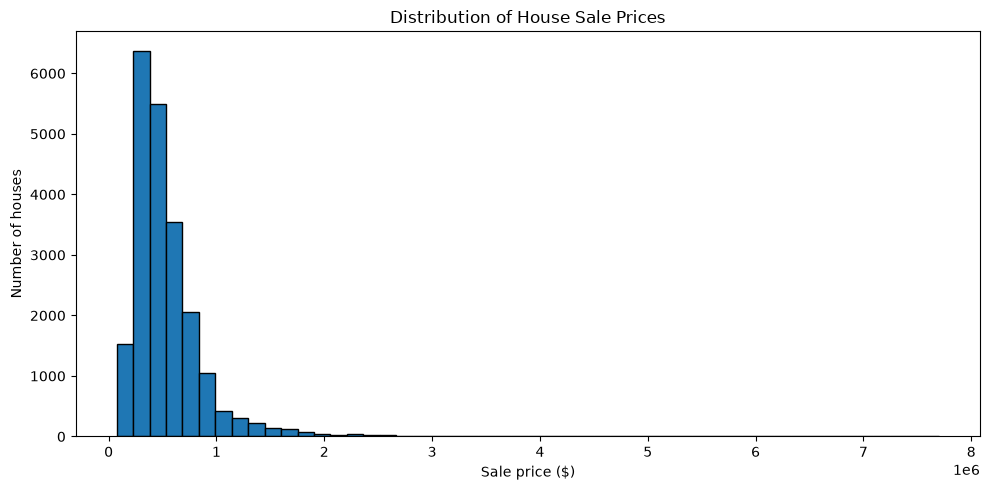

In [ ]:


plt.figure(figsize=(10, 5))

plt.hist(df_clean["price"], bins=50, edgecolor="black")

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale price ($)")
plt.ylabel("Number of houses")

plt.tight_layout()
plt.show()


          median_price  number_of_houses
bedrooms                                
0             288000.0                13
1             299000.0               199
2             374000.0              2760
3             413000.0              9824
4             549997.5              6882
5             620000.0              1601
6             650000.0               272
7             728580.0                38
8             700000.0                13
9             817000.0                 6
10            660000.0                 3
11            520000.0                 1
33            640000.0                 1


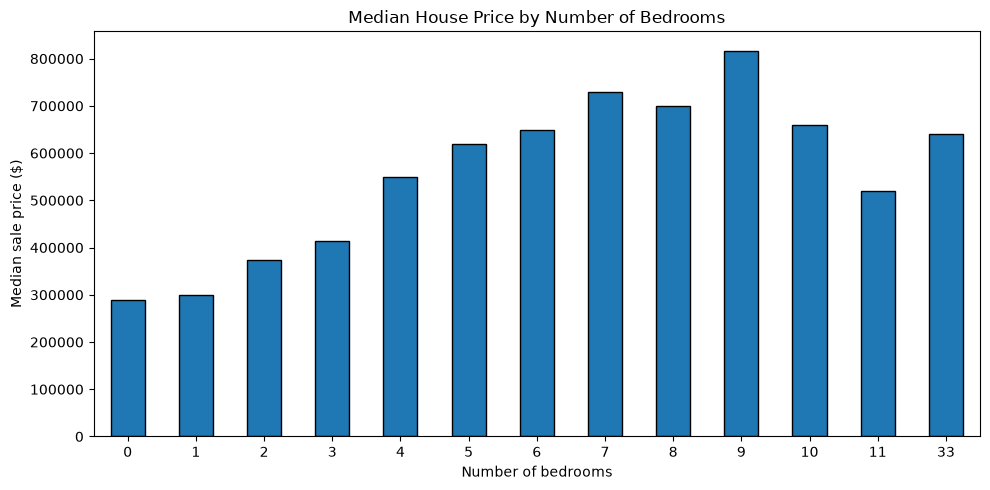

In [ ]:

# Calculate the median price and number of houses for each bedroom count.
bedroom_summary = (
    df_clean.groupby("bedrooms")["price"]
    .agg(median_price="median", number_of_houses="count")
)


print(bedroom_summary)


plt.figure(figsize=(10, 5))

bedroom_summary["median_price"].plot(kind="bar", edgecolor="black")

plt.title("Median House Price by Number of Bedrooms")
plt.xlabel("Number of bedrooms")
plt.ylabel("Median sale price ($)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


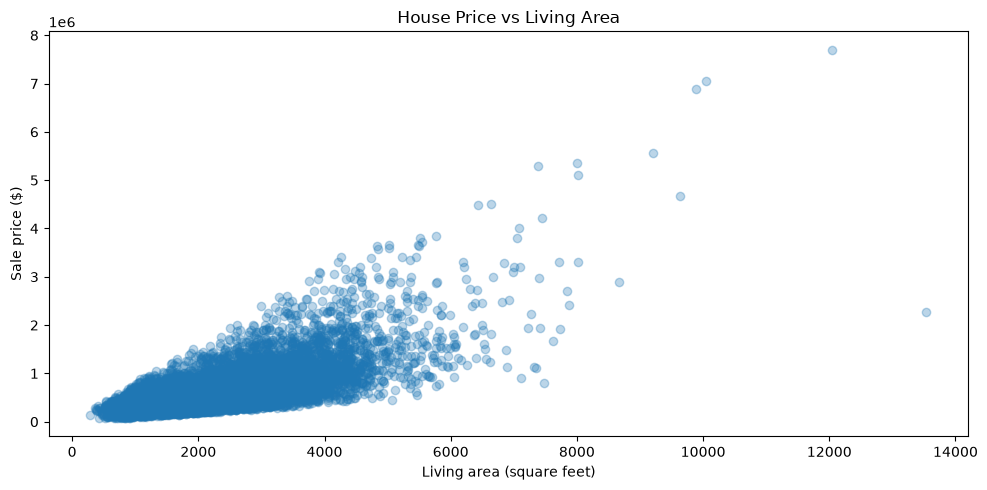

In [ ]:

plt.figure(figsize=(10, 5))

plt.scatter(
    df_clean["sqft_living"],
    df_clean["price"],
    alpha=0.3
)

plt.title("House Price vs Living Area")
plt.xlabel("Living area (square feet)")
plt.ylabel("Sale price ($)")

plt.tight_layout()
plt.show()


In [ ]:

largest_houses = (
    df_clean.nlargest(10, "sqft_living")
    [
        [
            "price",
            "sqft_living",
            "bedrooms",
            "bathrooms",
            "grade",
            "yr_built",
            "zipcode",
            "waterfront",
            "view"
        ]
    ]
)

print(largest_houses.to_string(index=False))


    price  sqft_living  bedrooms  bathrooms  grade  yr_built  zipcode  waterfront  view
2280000.0        13540         7       8.00     12      1999    98053           0     4
7700000.0        12050         6       8.00     13      1910    98102           0     3
7062500.0        10040         5       4.50     11      1940    98004           1     2
6885000.0         9890         6       7.75     13      2001    98039           0     4
4668000.0         9640         5       6.75     12      1983    98040           1     4
5570000.0         9200         5       5.75     13      2001    98039           0     0
2888000.0         8670         5       6.25     13      1965    98177           0     4
3300000.0         8020         5       6.25     11      2001    98006           0     0
5110800.0         8010         5       5.25     12      1999    98033           1     4
5350000.0         8000         5       5.00     12      2009    98004           0     4


### Investigate the Largest Properties

Inspect the two properties with the largest living areas, comparing their sale prices, lot sizes, grades, condition ratings, construction years, renovation records and other characteristics.

Although the properties have similar living areas, their sale prices differ considerably. This demonstrates that living area alone does not explain house prices; location, property grade, condition, land size and other features may also contribute.

Neither record is obviously invalid based on the available information. Retain both observations unless further investigation provides evidence of a data-quality problem.

In [ ]:

largest_two = (
    df_clean.nlargest(2, "sqft_living")
    [
        [
            "id",
            "date",
            "price",
            "sqft_living",
            "sqft_lot",
            "sqft_above",
            "sqft_basement",
            "bedrooms",
            "bathrooms",
            "floors",
            "grade",
            "condition",
            "yr_built",
            "yr_renovated",
            "zipcode",
            "waterfront",
            "view"
        ]
    ]
)

print(largest_two.to_string(index=False))


        id       date     price  sqft_living  sqft_lot  sqft_above  sqft_basement  bedrooms  bathrooms  floors  grade  condition  yr_built  yr_renovated  zipcode  waterfront  view
1225069038 2014-05-05 2280000.0        13540    307752        9410           4130         7        8.0     3.0     12          3      1999             0    98053           0     4
6762700020 2014-10-13 7700000.0        12050     27600        8570           3480         6        8.0     2.5     13          4      1910          1987    98102           0     3


In [ ]:

df_clean.loc[
    df_clean["bedrooms"] == 33,
    ["price", "bedrooms", "bathrooms", "sqft_living",
     "sqft_lot", "grade", "zipcode"]
]


,price,bedrooms,bathrooms,sqft_living,sqft_lot,grade,zipcode
15870,640000.0,33,1.75,1620,6000,7,98103


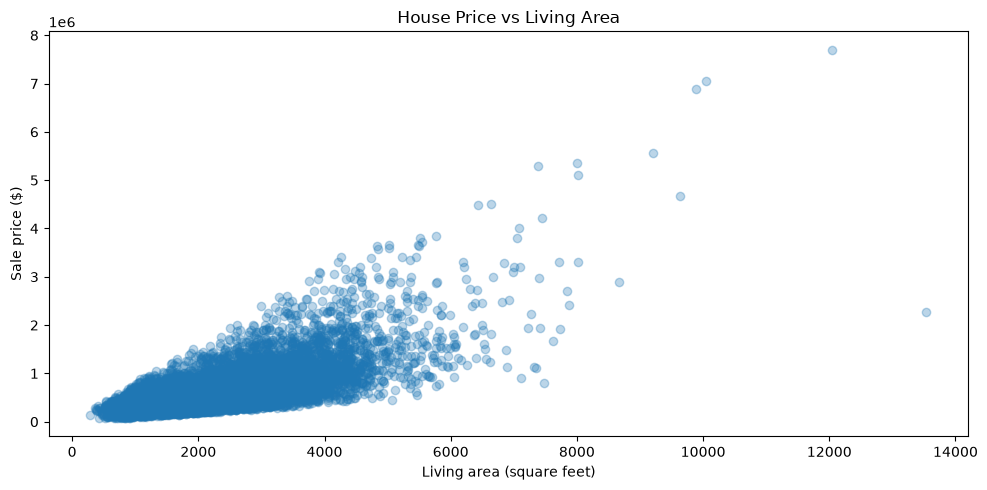

In [ ]:



plt.figure(figsize=(10, 5))

plt.scatter(
    df_clean["sqft_living"],
    df_clean["price"],
    alpha=0.3
)

plt.title("House Price vs Living Area")
plt.xlabel("Living area (square feet)")
plt.ylabel("Sale price ($)")

plt.tight_layout()
plt.show()


       median_price  number_of_houses
grade                                
1          142000.0                 1
3          262000.0                 3
4          205000.0                29
5          228700.0               242
6          275276.5              2038
7          375000.0              8981
8          510000.0              6068
9          720000.0              2615
10         914327.0              1134
11        1284000.0               399
12        1817500.0                90
13        2983000.0                13


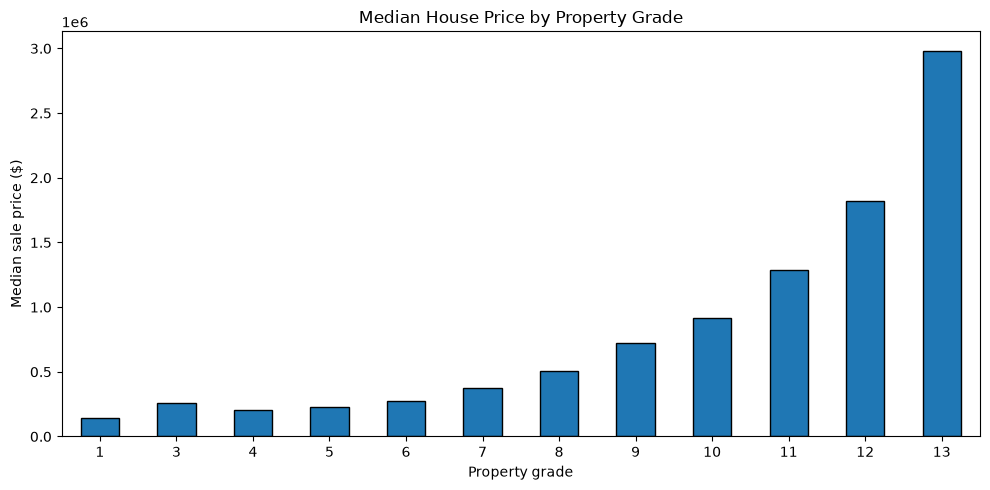

In [ ]:

grade_summary = (
    df_clean.groupby("grade")["price"]
    .agg(
        median_price="median",
        number_of_houses="count"
    )
)

print(grade_summary)

plt.figure(figsize=(10, 5))

grade_summary["median_price"].plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Median House Price by Property Grade")
plt.xlabel("Property grade")
plt.ylabel("Median sale price ($)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


### Analyse Correlations Between House Features

Select the sale price and important numerical property features, then calculate their pairwise Pearson correlation coefficients. Visualise the resulting correlation matrix as a heatmap, displaying the coefficients rounded to two decimal places.

Use the heatmap to investigate the strength and direction of linear relationships between sale price and features such as living area, grade, bedroom count and nearby-property living area. It also helps identify features that may contain overlapping information.

Correlation does not establish causation, and weak linear correlation does not necessarily mean a feature is unhelpful for a machine-learning model.

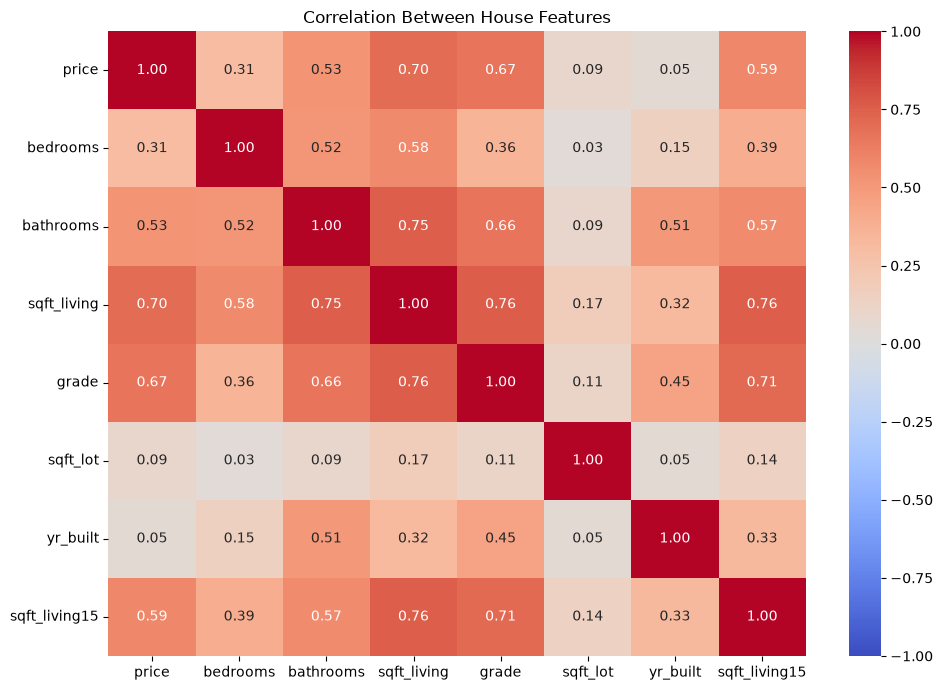

In [ ]:

correlation_columns = [
    "price",
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "grade",
    "sqft_lot",
    "yr_built",
    "sqft_living15"
]

correlation_matrix = df_clean[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between House Features")
plt.tight_layout()
plt.show()


### Build and Train a Decision Tree Pipeline

Create a machine-learning pipeline that prepares the features and trains a Decision Tree regression model.

- **Numeric pipeline:** fills missing numerical values using the median.
- **ZIP-code pipeline:** fills missing ZIP codes using the most frequent value and applies one-hot encoding to represent locations as categorical features.
- **ColumnTransformer:** applies the appropriate preprocessing to each feature group.
- **DecisionTreeRegressor:** learns patterns between the property features and house sale prices.

Fit the complete pipeline using the training features (`X_train`) and training targets (`y_train`). Keeping preprocessing inside the pipeline ensures that imputation values and encoding categories are learned from the training data.

This model can later be evaluated and compared with Linear Regression and Random Forest models.

In [ ]:

# Handle missing numeric values using the median.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Fill missing ZIP codes, then encode them.
zipcode_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature group.
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("zipcode", zipcode_pipeline, categorical_features)
])

# Build and train the decision tree.
decision_tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

decision_tree_pipeline.fit(X_train, y_train)

print("Decision Tree trained successfully!")


Decision Tree trained successfully!


### Evaluate the Decision Tree Model

Generate house-price predictions for the test features using the trained Decision Tree pipeline.

Evaluate the predictions using three regression metrics:

- **Mean Absolute Error (MAE):** measures the average absolute difference between actual and predicted house prices.
- **Root Mean Squared Error (RMSE):** penalises larger prediction errors more heavily than MAE.
- **R-squared (\(R^2\)):** measures how well the model predicts prices compared with a baseline that predicts the average actual price.

Print the results with appropriate formatting to make the monetary errors and \(R^2\) score easy to interpret. These metrics provide a basis for comparing the Decision Tree with other regression models.

In [ ]:

tree_predictions = decision_tree_pipeline.predict(X_test)

tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = root_mean_squared_error(y_test, tree_predictions)
tree_r2 = r2_score(y_test, tree_predictions)

print(f"Decision Tree MAE:  ${tree_mae:,.2f}")
print(f"Decision Tree RMSE: ${tree_rmse:,.2f}")
print(f"Decision Tree R²:   {tree_r2:.4f}")


Decision Tree MAE:  $102,051.60
Decision Tree RMSE: $182,958.37
Decision Tree R²:   0.7603


### Compare the Regression Models

Create a DataFrame comparing the performance of Linear Regression, Decision Tree and Random Forest models using three regression metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and \(R^2\).

MAE and RMSE measure prediction error, with lower values indicating better performance. \(R^2\) measures performance relative to a baseline that predicts the mean actual price, with higher values generally indicating better performance.

Comparing the metrics side by side helps identify which algorithm performed best on the evaluation dataset. For a fair comparison, all models should be evaluated on the same test split using consistent evaluation procedures, and the displayed metrics should come from the intended model runs rather than outdated hard-coded values.

In [ ]:
model_comparison = pd.DataFrame({
    "Algorithm": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        134528.81,
        tree_mae,
        67623.95
    ],
    "RMSE": [
        214901.60,
        tree_rmse,
        119518.64
    ],
    "R²": [
        0.6693,
        tree_r2,
        0.8977
    ]
})

model_comparison


,Algorithm,MAE,RMSE,R²
0,Linear Regression,134528.81000,214901.600000,0.669300
1,Decision Tree,102051.59667,182958.372239,0.760338
2,Random Forest,67623.95000,119518.640000,0.897700


### Build and Train the Linear Regression Pipeline

Create a scikit-learn pipeline that combines feature preprocessing with a Linear Regression model.

The preprocessing step handles missing values and converts ZIP codes into numerical features using one-hot encoding. The Linear Regression estimator then learns relationships between the prepared property features and their sale prices.

Fit the complete pipeline using `X_train` and `y_train`. By combining preprocessing and modelling in one pipeline, the same fitted transformations can be applied automatically when generating predictions for new data.

In [ ]:


# linear_pipeline = Pipeline([
#     ("preprocessor", preprocessor),
#     ("model", LinearRegression())
# ])

# linear_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['bedrooms','bathrooms','sqft_living',...,'sqft_lot15','sale_year', 'sale_month']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('zipcode', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This

### Define the Corrected Feature Preprocessor

Create separate preprocessing pipelines for numerical and categorical features.

The numeric pipeline replaces missing values with the median of each numerical feature. The categorical pipeline fills missing values with the most frequent category and applies one-hot encoding, configured to ignore previously unseen categories during transformation.

Combine the two pipelines using `ColumnTransformer`, applying each to its designated feature group. Store the result in `preprocessor_fixed` so that the corrected preprocessing configuration can be explicitly used by the appropriate model pipeline.

This cell defines the preprocessing configuration; it does not update or retrain existing models automatically.

In [ ]:

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_fixed = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("zipcode", categorical_pipeline, categorical_features)
])

### Train the Corrected Linear Regression Pipeline

Create a Linear Regression pipeline using the corrected `preprocessor_fixed` configuration. The preprocessing step imputes missing numerical values using the median and missing ZIP codes using the most frequent category, then one-hot encodes the ZIP codes.

Fit the complete pipeline using `X_train` and `y_train`. This trains the preprocessing steps and the Linear Regression estimator using the training data.

The fitted pipeline can then be used to generate predictions for the training and test datasets without manually preprocessing the features each time.

In [ ]:
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor_fixed),
    ("model", LinearRegression())
])

linear_pipeline.fit(X_train, y_train)

### Train the Random Forest Pipeline

Create a scikit-learn pipeline that combines the corrected feature preprocessing steps with a Random Forest regression model.

The Random Forest uses 200 trees, a maximum depth of 20, a minimum leaf size of 1, and `max_features=1.0`. A fixed random state supports reproducibility, while `n_jobs=-1` allows parallel computation across available CPU cores.

Fit the complete pipeline using `X_train` and `y_train`. The pipeline learns the preprocessing transformations from the training data and then trains the Random Forest to predict house sale prices.

This model can be evaluated against Linear Regression and Decision Tree models using the same training and test split.

In [ ]:


random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor_fixed),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=1,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_pipeline.fit(X_train, y_train)

### Compare Model Generalisation

Evaluate the fitted Linear Regression, Decision Tree and Random Forest pipelines on both the training and test datasets.

For each model, generate predictions and calculate Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and \(R^2\) for both datasets. Store the results in a DataFrame to make the comparisons easier to interpret.

Comparing training and test performance helps identify potential overfitting and assess how consistently each model performs on data it has not seen during training.

Use the results to understand the differences between the models, while relying on grouped cross-validation on the training data when selecting model settings. Reserve the test set primarily for final evaluation.

In [ ]:


models = {
    "Linear Regression": linear_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline
}
results = []

for name, model in models.items():
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    results.append({
        "Algorithm": name,
        "Train MAE": mean_absolute_error(y_train, train_predictions),
        "Test MAE": mean_absolute_error(y_test, test_predictions),
        "Train RMSE": root_mean_squared_error(y_train, train_predictions),
        "Test RMSE": root_mean_squared_error(y_test, test_predictions),
        "Train R²": r2_score(y_train, train_predictions),
        "Test R²": r2_score(y_test, test_predictions)
    })

generalisation_results = pd.DataFrame(results)
generalisation_results.round(3)

### Compare Model Generalisation

Evaluate the fitted Linear Regression, Decision Tree and final Random Forest pipelines on both the training and test datasets.

For each model, generate predictions and calculate Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and \(R^2\). Store the metrics in a DataFrame to compare training performance with test performance.

Comparing the two sets of results helps identify potential overfitting and assess how well each model generalises to houses it has not seen during training.

Use grouped cross-validation on the training data to support model selection, and use the held-out test set primarily for final evaluation.

In [ ]:

# Use the already-trained models.
models = {
    "Linear Regression": linear_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": final_pipeline
}

results = []

for name, model in models.items():
    train_predictions = model.predict(X_train)

    # Predict the houses held out for testing.
    test_predictions = model.predict(X_test)

    results.append({
        "Algorithm": name,
        "Train MAE": mean_absolute_error(y_train, train_predictions),
        "Test MAE": mean_absolute_error(y_test, test_predictions),
        "Train RMSE": root_mean_squared_error(y_train, train_predictions),
        "Test RMSE": root_mean_squared_error(y_test, test_predictions),
        "Train R²": r2_score(y_train, train_predictions),
        "Test R²": r2_score(y_test, test_predictions)
    })

generalisation_results = pd.DataFrame(results)

generalisation_results.round(3)


In [ ]:


# Compare the average absolute prediction error on the test set.
plt.figure(figsize=(9, 5))

plt.bar(
    generalisation_results["Algorithm"],
    generalisation_results["Test MAE"]
)

plt.title("House Price Prediction: Model Comparison")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Mean Absolute Error ($)")
plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'generalisation_results' is not defined

<Figure size 900x500 with 0 Axes>